In [20]:
# ============================================================
# STEP 1 - IMPORT LIBRARIES
# ============================================================

import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [21]:
# ============================================================
# STEP 2 - LOAD MODEL RESULTS
# ============================================================

prediction_results = pd.read_csv(
    "../data/processed/cv_prediction_results.csv"
)

model_comparison = pd.read_csv(
    "../data/processed/model_comparison.csv"
)

print("Prediction results loaded successfully.")
print("Prediction results shape:", prediction_results.shape)

print("\nModel comparison loaded successfully.")
print("Model comparison shape:", model_comparison.shape)

display(prediction_results)

Prediction results loaded successfully.
Prediction results shape: (15, 5)

Model comparison loaded successfully.
Model comparison shape: (3, 4)


,Student_ID,Actual_Outcome,Logistic Regression_Prediction,Decision Tree_Prediction,Random Forest_Prediction
0,ST001,Successful,Successful,Successful,Successful
1,ST002,Successful,Needs Practice,Needs Practice,Needs Practice
2,ST003,Successful,Successful,Successful,Successful
3,ST004,Waiting,Needs Practice,Needs Practice,Needs Practice
4,ST005,Successful,Successful,Successful,Successful
5,ST006,Needs Practice,Needs Practice,Needs Practice,Needs Practice
6,ST007,Needs Practice,Needs Practice,Needs Practice,Needs Practice
7,ST008,Successful,Successful,Successful,Successful
8,ST009,Needs Practice,Successful,Successful,Needs Practice
9,ST010,Successful,Successful,Successful,Successful


In [22]:
# ============================================================
# STEP 3 - VERIFY PREDICTION RESULTS
# ============================================================

print("Prediction result columns:")
print(prediction_results.columns.tolist())

print("\nNumber of students:")
print(prediction_results["Student_ID"].nunique())

print("\nActual outcome distribution:")
print(prediction_results["Actual_Outcome"].value_counts())

print("\nMissing values:")
print(prediction_results.isnull().sum())

Prediction result columns:
['Student_ID', 'Actual_Outcome', 'Logistic Regression_Prediction', 'Decision Tree_Prediction', 'Random Forest_Prediction']

Number of students:
15

Actual outcome distribution:
Actual_Outcome
Successful        9
Needs Practice    5
Waiting           1
Name: count, dtype: int64

Missing values:
Student_ID                        0
Actual_Outcome                    0
Logistic Regression_Prediction    0
Decision Tree_Prediction          0
Random Forest_Prediction          0
dtype: int64


In [23]:
# ============================================================
# STEP 4 - CALCULATE MODEL ACCURACY
# ============================================================

models = {
    "Logistic Regression": "Logistic Regression_Prediction",
    "Decision Tree": "Decision Tree_Prediction",
    "Random Forest": "Random Forest_Prediction"
}

accuracy_results = []

for model_name, prediction_column in models.items():

    accuracy = accuracy_score(
        prediction_results["Actual_Outcome"],
        prediction_results[prediction_column]
    )

    accuracy_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Accuracy (%)": accuracy * 100
    })

accuracy_results = pd.DataFrame(accuracy_results)

display(accuracy_results)

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.733333,73.333333
1,Decision Tree,0.733333,73.333333
2,Random Forest,0.800000,80.000000


In [24]:
# ============================================================
# STEP 5 - PRECISION, RECALL AND F1 SCORE
# ============================================================

evaluation_results = []

for model_name, prediction_column in models.items():

    y_true = prediction_results["Actual_Outcome"]
    y_pred = prediction_results[prediction_column]

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1
    })

evaluation_metrics = pd.DataFrame(evaluation_results)

display(evaluation_metrics)

,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,0.733333,0.680000,0.733333,0.705263
1,Decision Tree,0.733333,0.680000,0.733333,0.705263
2,Random Forest,0.800000,0.755556,0.800000,0.775758


In [25]:
# ============================================================
# STEP 6 - CLASSIFICATION REPORT
# ============================================================

for model_name, prediction_column in models.items():

    print("=" * 70)
    print(model_name)
    print("=" * 70)

    report = classification_report(
        prediction_results["Actual_Outcome"],
        prediction_results[prediction_column],
        zero_division=0
    )

    print(report)

Logistic Regression
                precision    recall  f1-score   support

Needs Practice       0.60      0.60      0.60         5
    Successful       0.80      0.89      0.84         9
       Waiting       0.00      0.00      0.00         1

      accuracy                           0.73        15
     macro avg       0.47      0.50      0.48        15
  weighted avg       0.68      0.73      0.71        15

Decision Tree
                precision    recall  f1-score   support

Needs Practice       0.60      0.60      0.60         5
    Successful       0.80      0.89      0.84         9
       Waiting       0.00      0.00      0.00         1

      accuracy                           0.73        15
     macro avg       0.47      0.50      0.48        15
  weighted avg       0.68      0.73      0.71        15

Random Forest
                precision    recall  f1-score   support

Needs Practice       0.67      0.80      0.73         5
    Successful       0.89      0.89      0.89    


Logistic Regression - Confusion Matrix
[[8 1 0]
 [2 3 0]
 [0 1 0]]


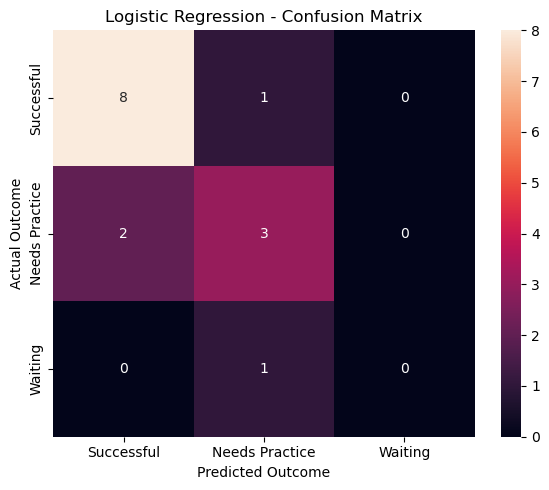


Decision Tree - Confusion Matrix
[[8 1 0]
 [2 3 0]
 [0 1 0]]


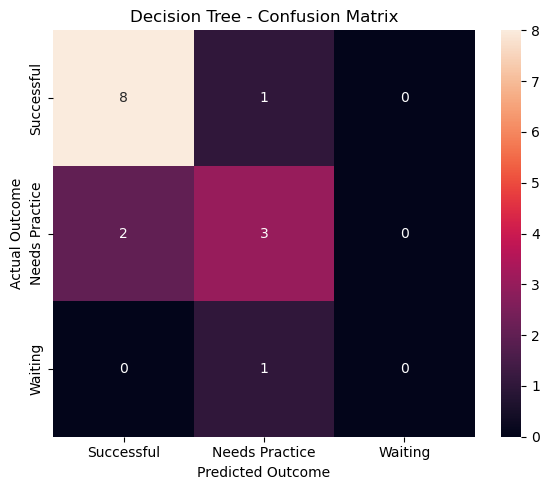


Random Forest - Confusion Matrix
[[8 1 0]
 [1 4 0]
 [0 1 0]]


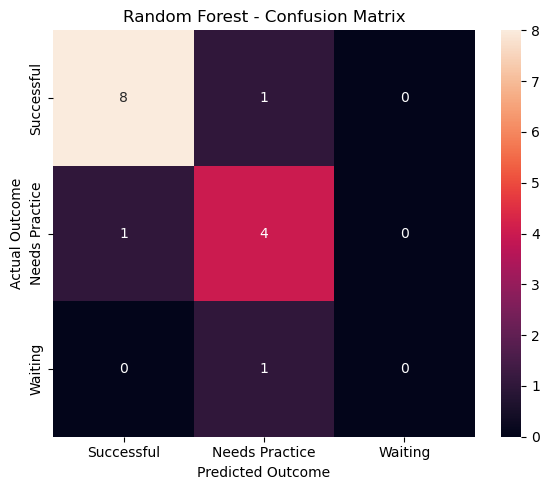

In [26]:
# ============================================================
# STEP 7 - CONFUSION MATRICES
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Get the outcome classes
class_labels = [
    "Successful",
    "Needs Practice",
    "Waiting"
]

# Generate confusion matrix for each model
for model_name, prediction_column in models.items():

    cm = confusion_matrix(
        prediction_results["Actual_Outcome"],
        prediction_results[prediction_column],
        labels=class_labels
    )

    print(f"\n{'=' * 60}")
    print(f"{model_name} - Confusion Matrix")
    print(f"{'=' * 60}")

    print(cm)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=class_labels,
        yticklabels=class_labels
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Outcome")
    plt.ylabel("Actual Outcome")

    plt.tight_layout()
    plt.show()

In [27]:
# ============================================================
# STEP 8 - MODEL PERFORMANCE COMPARISON
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

evaluation_results = []

for model_name, prediction_column in models.items():

    y_true = prediction_results["Actual_Outcome"]
    y_pred = prediction_results[prediction_column]

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1
    })

evaluation_results = pd.DataFrame(evaluation_results)

evaluation_results["Accuracy (%)"] = (
    evaluation_results["Accuracy"] * 100
)

evaluation_results["Precision (%)"] = (
    evaluation_results["Precision"] * 100
)

evaluation_results["Recall (%)"] = (
    evaluation_results["Recall"] * 100
)

evaluation_results["F1 Score (%)"] = (
    evaluation_results["F1_Score"] * 100
)

display(evaluation_results)

,Model,Accuracy,Precision,Recall,F1_Score,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Logistic Regression,0.733333,0.680000,0.733333,0.705263,73.333333,68.000000,73.333333,70.526316
1,Decision Tree,0.733333,0.680000,0.733333,0.705263,73.333333,68.000000,73.333333,70.526316
2,Random Forest,0.800000,0.755556,0.800000,0.775758,80.000000,75.555556,80.000000,77.575758


In [28]:
# ============================================================
# STEP 9 - RANK MODELS
# ============================================================

model_ranking = evaluation_results.sort_values(
    by="F1_Score",
    ascending=False
).reset_index(drop=True)

model_ranking["Rank"] = range(
    1,
    len(model_ranking) + 1
)

print("Model Performance Ranking:")
display(model_ranking)

Model Performance Ranking:


,Model,Accuracy,Precision,Recall,F1_Score,Accuracy (%),Precision (%),Recall (%),F1 Score (%),Rank
0,Random Forest,0.800000,0.755556,0.800000,0.775758,80.000000,75.555556,80.000000,77.575758,1
1,Logistic Regression,0.733333,0.680000,0.733333,0.705263,73.333333,68.000000,73.333333,70.526316,2
2,Decision Tree,0.733333,0.680000,0.733333,0.705263,73.333333,68.000000,73.333333,70.526316,3


In [29]:
# ============================================================
# STEP 10 - SELECT BEST MODEL
# ============================================================

best_model_name = model_ranking.loc[0, "Model"]
best_accuracy = model_ranking.loc[0, "Accuracy"]
best_f1 = model_ranking.loc[0, "F1_Score"]

print("=" * 60)
print("BEST MODEL")
print("=" * 60)

print(f"Model: {best_model_name}")
print(f"Accuracy: {best_accuracy * 100:.2f}%")
print(f"F1 Score: {best_f1 * 100:.2f}%")

BEST MODEL
Model: Random Forest
Accuracy: 80.00%
F1 Score: 77.58%


In [30]:
# ============================================================
# STEP 11 - SAVE EVALUATION RESULTS
# ============================================================

import os

os.makedirs("../data/processed", exist_ok=True)

evaluation_results.to_csv(
    "../data/processed/model_evaluation_metrics.csv",
    index=False
)

model_ranking.to_csv(
    "../data/processed/model_ranking.csv",
    index=False
)

print("Evaluation metrics saved successfully.")
print("Model ranking saved successfully.")

Evaluation metrics saved successfully.
Model ranking saved successfully.


CONFUSION MATRIX — Logistic Regression
[[3 2 0]
 [1 8 0]
 [1 0 0]]


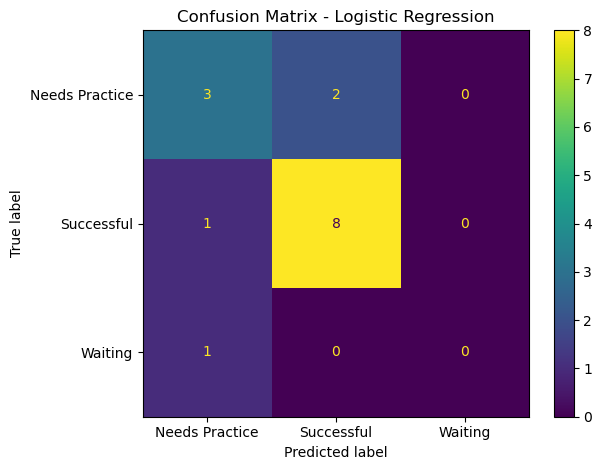

CONFUSION MATRIX — Decision Tree
[[3 2 0]
 [1 8 0]
 [1 0 0]]


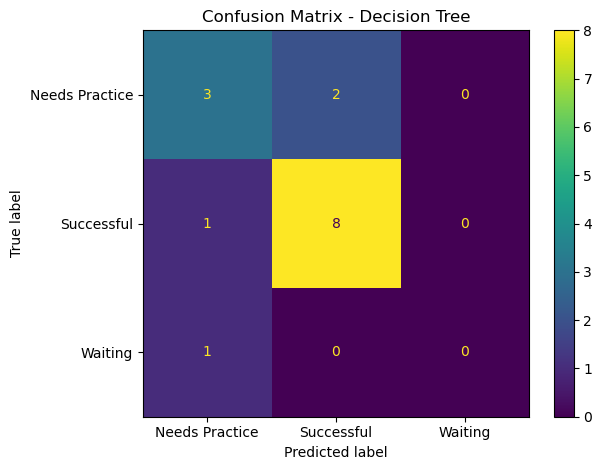

CONFUSION MATRIX — Random Forest
[[4 1 0]
 [1 8 0]
 [1 0 0]]


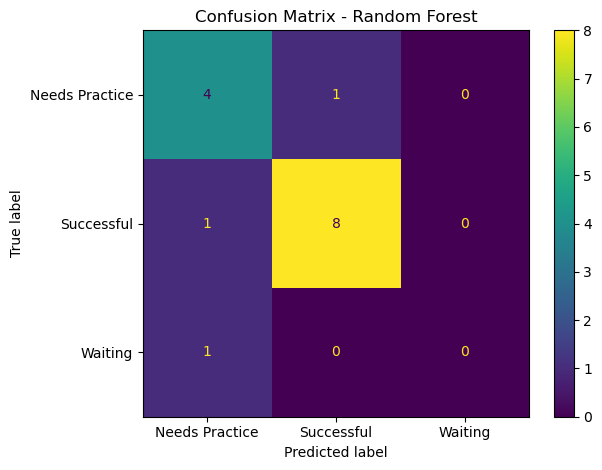

In [31]:
# ============================================================
# STEP 12 — CONFUSION MATRICES
# ============================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_labels = [
    "Needs Practice",
    "Successful",
    "Waiting"
]

for model_name, prediction_column in models.items():

    y_true = prediction_results["Actual_Outcome"]
    y_pred = prediction_results[prediction_column]

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_labels
    )

    print("=" * 60)
    print(f"CONFUSION MATRIX — {model_name}")
    print("=" * 60)

    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    disp.plot()

    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1_Score,Accuracy (%),Precision (%),Recall (%),F1 Score (%),Rank
0,Random Forest,0.800000,0.755556,0.800000,0.775758,80.000000,75.555556,80.000000,77.575758,1
1,Logistic Regression,0.733333,0.680000,0.733333,0.705263,73.333333,68.000000,73.333333,70.526316,2
2,Decision Tree,0.733333,0.680000,0.733333,0.705263,73.333333,68.000000,73.333333,70.526316,3


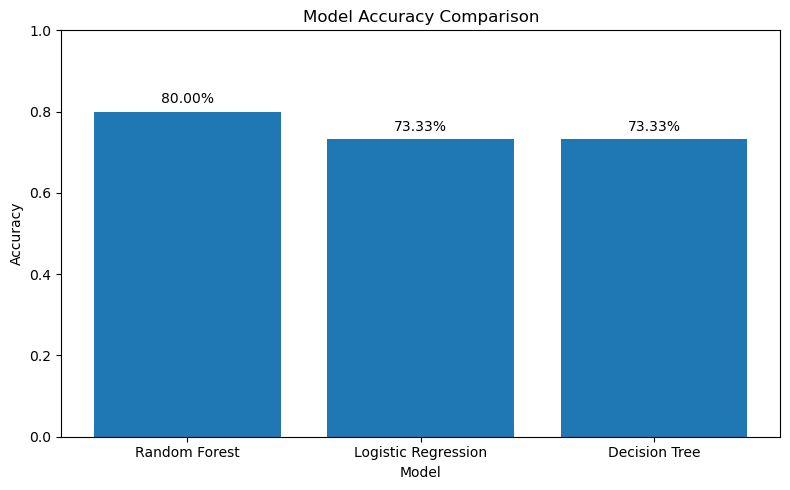

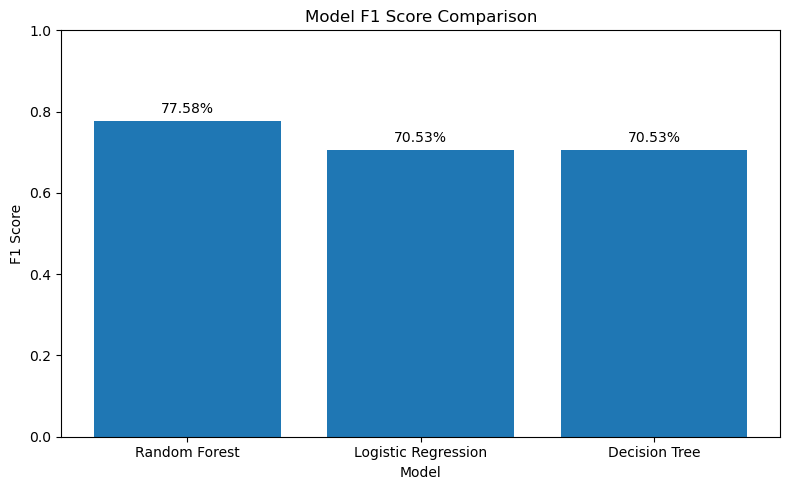

Performance comparison completed successfully.
Accuracy chart saved.
F1 score chart saved.


In [32]:
# ============================================================
# STEP 13 — MODEL PERFORMANCE COMPARISON
# ============================================================

import matplotlib.pyplot as plt

# Display model ranking
print("=" * 60)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)

display(model_ranking)

# ------------------------------------------------------------
# Accuracy Comparison
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    model_ranking["Model"],
    model_ranking["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)

for i, value in enumerate(model_ranking["Accuracy"]):
    plt.text(
        i,
        value + 0.02,
        f"{value * 100:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "../data/processed/model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# F1 Score Comparison
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    model_ranking["Model"],
    model_ranking["F1_Score"]
)

plt.title("Model F1 Score Comparison")
plt.xlabel("Model")
plt.ylabel("F1 Score")

plt.ylim(0, 1)

for i, value in enumerate(model_ranking["F1_Score"]):
    plt.text(
        i,
        value + 0.02,
        f"{value * 100:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "../data/processed/model_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Performance comparison completed successfully.")
print("Accuracy chart saved.")
print("F1 score chart saved.")

In [33]:
# ============================================================
# STEP 14 — FINAL MODEL SUMMARY
# ============================================================

best_model = model_ranking.iloc[0]

print("=" * 60)
print("FINAL MODEL SELECTION")
print("=" * 60)

print(f"Best Model   : {best_model['Model']}")
print(f"Accuracy     : {best_model['Accuracy'] * 100:.2f}%")
print(f"F1 Score     : {best_model['F1_Score'] * 100:.2f}%")

print("=" * 60)

print("\nReason for selection:")
print(
    f"{best_model['Model']} achieved the highest accuracy "
    f"and F1 score among the evaluated models."
)

FINAL MODEL SELECTION
Best Model   : Random Forest
Accuracy     : 80.00%
F1 Score     : 77.58%

Reason for selection:
Random Forest achieved the highest accuracy and F1 score among the evaluated models.


In [34]:
# ============================================================
# STEP 15 — FINAL EVALUATION VERIFICATION
# ============================================================

import os

print("=" * 60)
print("FINAL EVALUATION VERIFICATION")
print("=" * 60)

# Best model
print("\nBest Model:")
print(f"Model    : {best_model['Model']}")
print(f"Accuracy : {best_model['Accuracy'] * 100:.2f}%")
print(f"F1 Score : {best_model['F1_Score'] * 100:.2f}%")

# Number of evaluated students
print("\nEvaluation Dataset:")
print(f"Number of students evaluated: {len(prediction_results)}")

if "Student_ID" in prediction_results.columns:
    print(
        f"Unique students evaluated: "
        f"{prediction_results['Student_ID'].nunique()}"
    )

# Check saved files
print("\nSaved Evaluation Files:")

files_to_check = [
    "../data/processed/model_evaluation_metrics.csv",
    "../data/processed/model_ranking.csv",
    "../data/processed/cv_prediction_results.csv",
    "../data/processed/model_comparison.csv",
    "../data/processed/model_accuracy_comparison.png",
    "../data/processed/model_f1_comparison.png"
]

for file_path in files_to_check:
    if os.path.exists(file_path):
        print(f"✓ {os.path.basename(file_path)}")
    else:
        print(f"✗ {os.path.basename(file_path)} — NOT FOUND")

print("\n" + "=" * 60)
print("MODEL EVALUATION COMPLETED")
print("=" * 60)

FINAL EVALUATION VERIFICATION

Best Model:
Model    : Random Forest
Accuracy : 80.00%
F1 Score : 77.58%

Evaluation Dataset:
Number of students evaluated: 15
Unique students evaluated: 15

Saved Evaluation Files:
✓ model_evaluation_metrics.csv
✓ model_ranking.csv
✓ cv_prediction_results.csv
✓ model_comparison.csv
✓ model_accuracy_comparison.png
✓ model_f1_comparison.png

MODEL EVALUATION COMPLETED
